In [2]:
import pandas
import numpy
import matplotlib
import nltk
import spacy
import Sastrawi
import sklearn

print("Environment NLP siap digunakan.")


Environment NLP siap digunakan.


In [1]:
import sys
print(sys.executable)


d:\Projects\Natural Language Processing\.venv\Scripts\python.exe


In [ ]:
# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ACER\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ACER\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [ ]:
# 3. Membaca Dataset
df = pd.read_csv("../dataset.csv")
print("Dataset berhasil dibaca!")
print("Data berhasil dimuat ke dalam DataFrame df.")

Dataset berhasil dibaca!
Data berhasil dimuat ke dalam DataFrame df.


In [ ]:
# 4. Melihat Data Awal

# 10 data pertama
df.head(5)

,userName,content,score,at,appVersion
0,Yuga Edit,akun gopay saya di blok,1,2022-01-21 10:52:12,4.9.3
1,ff burik,Lambat sekali sekarang ini bosssku apk gojek g...,3,2021-11-30 15:40:38,4.9.3
2,Anisa Suci Rahmayuliani,Kenapa sih dari kemarin sy buka aplikasi gojek...,4,2021-11-29 22:58:12,4.9.3
3,naoki yakuza,Baru download gojek dan hape baru trus ditop u...,1,2022-09-03 15:21:17,4.9.3
4,Trio Sugianto,Mantap,5,2022-01-15 10:05:27,4.9.3


In [ ]:
# 5 data terakhir
df.tail(5)

,userName,content,score,at,appVersion
224997,Sad Gamer,Gofood Biaya lain2ya gak ngotak mending hujan2...,1,2023-02-15 9:37:58,4.0.0
224998,fadhil fadil,Yok lah,5,2021-12-11 12:28:20,4.0.0
224999,g sugiarto,Sempurna,5,2022-03-14 1:45:39,4.0.0
225000,J i H A D 'B E,GOJEK LAMA LAMA GAK JELAS LAGI PESEN MASA MAP...,1,2021-12-24 8:48:51,4.0.0
225001,Ria Heria,Good,5,2022-03-17 14:33:34,4.0.0


In [35]:
# 5. Informasi Dataset
df.info()
df.shape
print("\n=== UKURAN DATASET ===")
print("Jumlah baris dan kolom:", df.shape)
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

<class 'pandas.DataFrame'>
RangeIndex: 225002 entries, 0 to 225001
Data columns (total 5 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   userName    225002 non-null  str  
 1   content     224923 non-null  str  
 2   score       225002 non-null  int64
 3   at          225002 non-null  str  
 4   appVersion  225002 non-null  str  
dtypes: int64(1), str(4)
memory usage: 8.6 MB

=== UKURAN DATASET ===
Jumlah baris dan kolom: (225002, 5)
Jumlah baris: 225002
Jumlah kolom: 5


In [39]:
# 6. Melihat nama kolom
df.columns
print("Nama kolom pada dataset:")

for kolom in df.columns:
    print("-", kolom)

Nama kolom pada dataset:
- userName
- content
- score
- at
- appVersion


In [ ]:
# 7. Jumlah dokumen
jumlah_dokumen = len(df)
print("Jumlah dokumen:", jumlah_dokumen)

Jumlah dokumen: 225002


In [47]:
text_column = "content"
texts = df[text_column]

print("PEMILIHAN KOLOM TEKS")
print("Kolom teks yang dipilih:", text_column)
print("Jumlah teks:", len(texts))

print("\n5 contoh teks")
for text in texts.head(5):
    print(text)
    print("-" * 80)

PEMILIHAN KOLOM TEKS
Kolom teks yang dipilih: content
Jumlah teks: 225002

5 contoh teks
akun gopay saya di blok
--------------------------------------------------------------------------------
Lambat sekali sekarang ini bosssku apk gojek gk kaya dulu
--------------------------------------------------------------------------------
Kenapa sih dari kemarin sy buka aplikasi gojek malah keluar sendiri terus Saya kasih bintang 2 dulu kalo sudah normal sy kasih bintang 7
--------------------------------------------------------------------------------
Baru download gojek dan hape baru trus ditop u gopay transaksi dialfamart transaksi bloked transaksilaporan di pusat bantuan gak jelas yang ditanyakan apa jawaban lainlama lama gojek dikelola Tokopedia udah nyimpangapa gojek anak bangsa seperti dulu apa punya Tokopedia
--------------------------------------------------------------------------------
Mantap
--------------------------------------------------------------------------------


In [53]:
# 9. Memeriksa misiing value
# a. Memeriksa seluruh kolom
print("Missing value setiap kolom:")
print(df.isnull().sum())


Missing value setiap kolom:
userName       0
content       79
score          0
at             0
appVersion     0
dtype: int64


In [111]:
# Memeriksa khusus pada kolom content:
jumlah_kosong = df["content"].isnull().sum()
print("Jumlah teks yang kosong:", jumlah_kosong)

Jumlah teks yang kosong: 0


In [112]:
# b. Menghapus data kosong
df = df.dropna(subset=[text_column])
df[text_column].isnull().sum()

np.int64(0)

In [ ]:
# c.sMemeriksa Duplikasi
print("Jumlah baris duplikat:", df.duplicated().sum())

Jumlah baris duplikat: 0


In [118]:
# d.Memeriksa Duplikasi pada Kolom Teks
print("Jumlah duplikat:", df[text_column].duplicated().sum())

Jumlah duplikat: 0


In [117]:
# Menghapus duplikasi:
df = df.drop_duplicates(subset=[text_column])

In [108]:
# Memeriksa kembali duplikasi
print("Jumlah duplikat setelah dihapus:", df[text_column].duplicated().sum())

Jumlah duplikat setelah dihapus: 0


In [103]:
# Membaca ulang dataset asli
df = pd.read_csv("../dataset.csv")

print("Jumlah data sebelum menghapus duplikasi:", len(df))
print("Jumlah duplikat pada kolom teks:",
      df[text_column].duplicated().sum())

Jumlah data sebelum menghapus duplikasi: 225002
Jumlah duplikat pada kolom teks: 87066


In [120]:
# 11. Menghitung Jumlah Karakter
df["jumlah_karakter"] = df[text_column].astype(str).apply(len)
df[[text_column, "jumlah_karakter"]].head()

,content,jumlah_karakter
0,akun gopay saya di blok,23
1,Lambat sekali sekarang ini bosssku apk gojek g...,57
2,Kenapa sih dari kemarin sy buka aplikasi gojek...,136
3,Baru download gojek dan hape baru trus ditop u...,269
4,Mantap,6


In [123]:
# 12. Menghitung Jumlah Kata
df["jumlah_kata"] = df[text_column].astype(str).apply(
    lambda x: len(x.split())
)
df[[text_column, "jumlah_kata"]].head()


,content,jumlah_kata
0,akun gopay saya di blok,5
1,Lambat sekali sekarang ini bosssku apk gojek g...,10
2,Kenapa sih dari kemarin sy buka aplikasi gojek...,24
3,Baru download gojek dan hape baru trus ditop u...,39
4,Mantap,1


In [124]:
df["jumlah_kata"].describe()

count    137935.000000
mean         12.891028
std          13.913406
min           1.000000
25%           4.000000
50%           8.000000
75%          17.000000
max         104.000000
Name: jumlah_kata, dtype: float64

In [131]:
# 13. Menghitung Jumlah Kalimat
import nltk

print("Jumlah kalimat pada 10 ulasan pertama:")
print(df["content"].astype(str).apply(
    lambda x: len(nltk.sent_tokenize(x))
).head(5))

Jumlah kalimat pada 10 ulasan pertama:
0    1
1    1
2    1
3    1
4    1
Name: content, dtype: int64


In [132]:
# 14. Statistik Corpus
print("Jumlah dokumen :", len(df))
print("Jumlah kata    :", df["jumlah_kata"].sum())
print("Jumlah kalimat :", df["jumlah_kalimat"].sum())
print("Jumlah karakter:", df["jumlah_karakter"].sum())

Jumlah dokumen : 137935
Jumlah kata    : 1778124
Jumlah kalimat : 137935
Jumlah karakter: 10866997


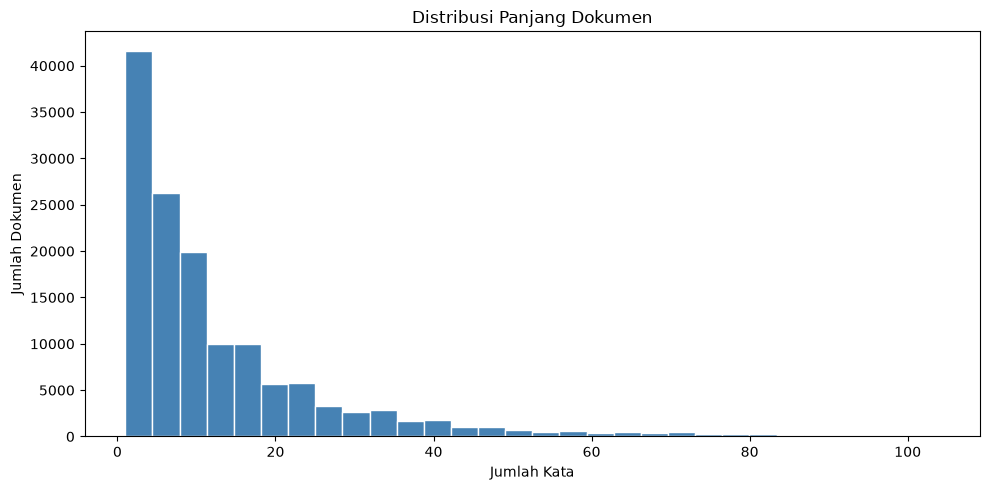

In [146]:
# 15. Visualisasi Distribusi Panjang Dokumen
plt.figure(figsize=(10, 5))
plt.hist(df["jumlah_kata"], bins=30, color="steelblue", edgecolor="white")
plt.xlabel("Jumlah Kata")
plt.ylabel("Jumlah Dokumen")
plt.title("Distribusi Panjang Dokumen")
plt.tight_layout()
plt.show()


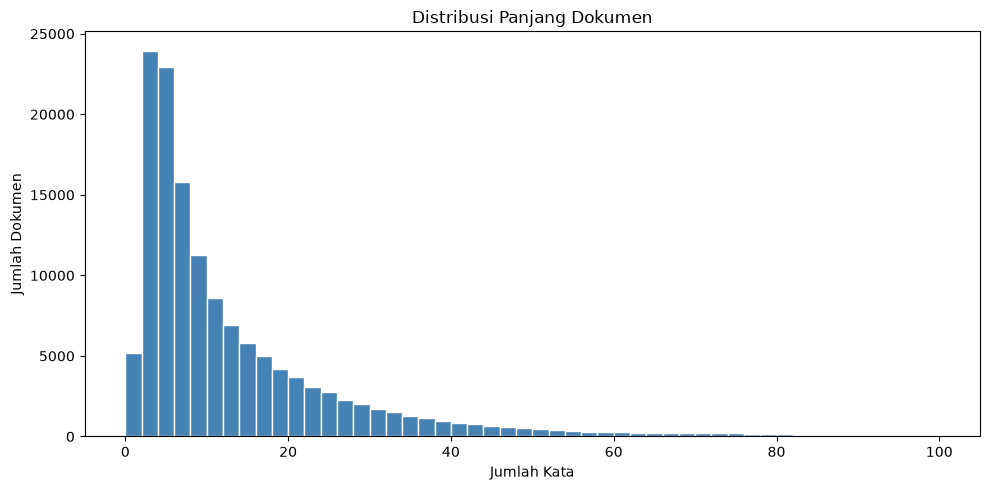

In [144]:
# 15. Visualisasi Distribusi Panjang Dokumen
df["jumlah_kata"] = df["content"].fillna("").astype(str).str.split().str.len()

plt.figure(figsize=(10, 5))
plt.hist(df["jumlah_kata"], bins=50, range=(0, 100),
         color="steelblue", edgecolor="white")

plt.xlabel("Jumlah Kata")
plt.ylabel("Jumlah Dokumen")
plt.title("Distribusi Panjang Dokumen")
plt.tight_layout()
plt.show()

score
5    68216
1    43690
4     9004
2     8607
3     8418
Name: count, dtype: int64


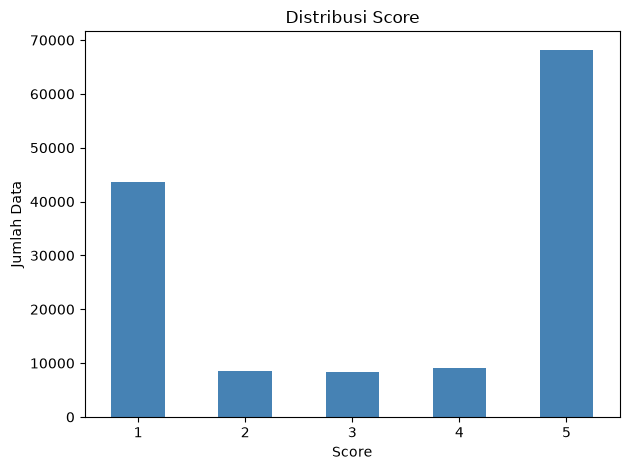

In [143]:
# Ganti "label" dengan nama kolom label di dataset Anda
print(df["score"].value_counts())
df["score"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue"
)

plt.xlabel("Score")
plt.ylabel("Jumlah Data")
plt.title("Distribusi Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [137]:
# Distribusi Label (Jika Ada)
# Dataset tidak memiliki kolom label,
# sehingga analisis distribusi label tidak dilakukan.

In [ ]:
print("E. TUGAS ANALISIS")
print("1. Nama dataset: Ulasan Aplikasi Gojek")
print("2. Sumber dataset: Kaggle")
print("3. Jumlah dokumen:", len(df))
print("4. Jumlah kolom:", len(df.columns))
print("5. Kolom teks: content")
print("6. Missing value:", df.isnull().sum().sum())
print("7. Data duplikat:", df.duplicated(subset=["content"]).sum())

kata = df["content"].fillna("").astype(str).str.split().str.len()

print("8. Rata-rata kata per dokumen:", round(kata.mean(), 2))
print("9. Dokumen terpendek:", kata.min(), "kata")
print("10. Dokumen terpanjang:", kata.max(), "kata")

print("11. Label sentimen: Tidak ada label khusus")
print("12. Distribusi rating:")
print(df["score"].value_counts().sort_index())

print("13. Karakteristik bahasa: Ulasan menggunakan bahasa sehari-hari, berisi pengalaman, pujian, dan keluhan pengguna.")
# Catatan: sebelumnya, data awal berjumlah 225.002 baris dan setelah duplikat berdasarkan content dihapus menjadi 137.935 baris.
#  Kalau kamu juga menghapus nilai kosong, hasil akhirnya bisa berbeda.
#  Jadi, jalankan kode ini setelah semua proses pembersihan selesai agar hasilnya sesuai dengan dataset akhir.

E. TUGAS ANALISIS
1. Nama dataset: Ulasan Aplikasi Gojek
2. Sumber dataset: Kaggle
3. Jumlah dokumen: 137935
4. Jumlah kolom: 8
5. Kolom teks: content
6. Missing value: 0
7. Data duplikat: 0
8. Rata-rata kata per dokumen: 12.89
9. Dokumen terpendek: 1 kata
10. Dokumen terpanjang: 104 kata
11. Label sentimen: Tidak ada label khusus
12. Distribusi rating:
score
1    43690
2     8607
3     8418
4     9004
5    68216
Name: count, dtype: int64
13. Karakteristik bahasa: Ulasan menggunakan bahasa sehari-hari, berisi pengalaman, pujian, dan keluhan pengguna.


In [ ]:
#G. Pertanyaan Diskusi
1. Mengapa eksplorasi corpus penting sebelum memulai proses NLP?
Eksplorasi corpus penting untuk mengetahui kondisi data sebelum diolah, seperti jumlah data, isi teks, missing value, duplikasi, dan panjang teks. Dengan begitu, kita bisa menentukan langkah pengolahan data yang sesuai.
2. Apa perbedaan dokumen, kalimat, kata, dan karakter dalam konteks NLP?
- Dokumen: satu teks utuh, misalnya satu ulasan pengguna.
- Kalimat: bagian dari dokumen yang berisi satu pernyataan.
- Kata: susunan huruf yang memiliki makna, misalnya “aplikasi”.
- Karakter: setiap huruf, angka, spasi, atau tanda baca dalam teks.
3. Apakah dataset yang seimbang (balanced) selalu lebih baik?
Tidak selalu. Dataset seimbang dapat membantu model mempelajari setiap kelas dengan lebih baik. Namun, dataset tidak seimbang juga bisa digunakan, tergantung tujuan analisis dan kondisi data.
4. Mengapa perlu memeriksa missing value dan duplikasi?
Missing value perlu diperiksa karena data yang kosong dapat mengganggu proses analisis. Duplikasi perlu diperiksa agar data yang sama tidak dihitung berulang kali dan memengaruhi hasil analisis.
5. Apa yang dapat disimpulkan dari distribusi panjang dokumen?
Distribusi panjang dokumen menunjukkan variasi jumlah kata dalam setiap teks. Dari distribusi tersebut, kita dapat mengetahui apakah sebagian besar teks pendek atau panjang sehingga bisa menentukan metode pengolahan teks yang sesuai.